# 67 · The return knob: ask for more, get more (up to what the data contains)

In [1]:
import sys, numpy as np, torch, matplotlib.pyplot as plt
import importlib.util, os

spec = importlib.util.spec_from_file_location("dtnb", os.path.abspath("dt_lib.py"))
dtnb = importlib.util.module_from_spec(spec); spec.loader.exec_module(dtnb)
device = dtnb.device

In [2]:
data = list(np.load("generated/pendulum_offline.npy", allow_pickle=True))
returns = np.array([e["rew"].sum() for e in data])
dt = dtnb.DecisionTransformer().to(device)
dt.load_state_dict(torch.load("generated/dt_pendulum.pt", map_location=device)); dt.eval()
print(f"dataset returns: min {returns.min():.0f}  mean {returns.mean():.0f}  max {returns.max():.0f}")

dataset returns: min -1903  mean -821  max -1


S07_Sequence_Models/dt_lib.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tf = nn.TransformerEncoder(layer, n_layer)


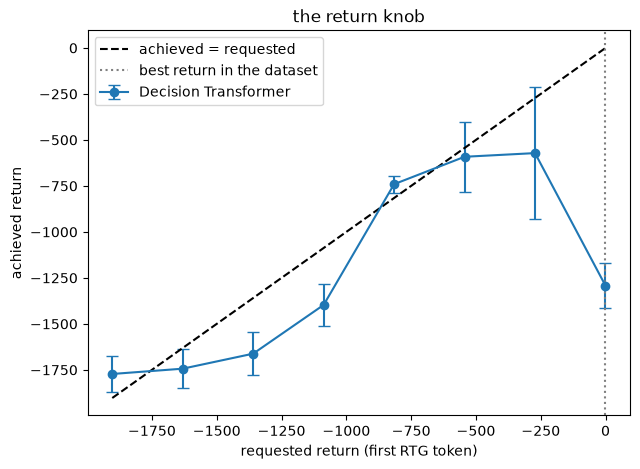

requested   -1903 -> achieved   -1772
requested   -1631 -> achieved   -1744
requested   -1359 -> achieved   -1662
requested   -1088 -> achieved   -1397
requested    -816 -> achieved    -741
requested    -544 -> achieved    -592
requested    -272 -> achieved    -572
requested      -0 -> achieved   -1292


In [3]:
targets = np.linspace(returns.min(), returns.max() + 0.5 * abs(returns.max()), 8)
achieved = np.array([[dtnb.rollout_dt(dt, g, seed=2000 + s) for s in range(5)] for g in targets])
plt.figure(figsize=(7, 5))
plt.errorbar(targets, achieved.mean(1), yerr=achieved.std(1), marker="o", capsize=4, label="Decision Transformer")
lim = [targets.min(), targets.max()]
plt.plot(lim, lim, "k--", label="achieved = requested")
plt.axvline(returns.max(), c="gray", ls=":", label="best return in the dataset")
plt.xlabel("requested return (first RTG token)"); plt.ylabel("achieved return"); plt.legend(); plt.title("the return knob"); plt.show()
for g, a in zip(targets, achieved.mean(1)):
    print(f"requested {g:7.0f} -> achieved {a:7.0f}")

### Watch the knob
The same pendulum and the same network, given three different first return-to-go tokens.

In [4]:
from vlacourse import showcase as sc
asks = {"ask: worst return in the data": returns.min(), "ask: average return": returns.mean(), "ask: best return in the data": returns.max()}
clips, labels = [], []
for name, g in asks.items():
    fr = []; got = dtnb.rollout_dt(dt, g, seed=2003, frames=fr)
    clips.append(fr[::2]); labels.append(f"{name} ({g:.0f}) -> got {got:.0f}")
sc.side_by_side(clips, labels, title="67 the return knob", fps=25, footer="same policy, same start: only the requested return changes")

[array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]]], shape=(300, 900, 3), dtype=uint8),
 array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0,